In [1]:
%pip install easyocr opencv-python pillow matplotlib

   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   --- ------------------------------------ 0.3/2.9 MB ? eta -:--:--
   ---------- ----------------------------- 0.8/2.9 MB 2.0 MB/s eta 0:00:02
   -------------- ------------------------- 1.0/2.9 MB 1.7 MB/s eta 0:00:02
   --------------------- ------------------ 1.6/2.9 MB 2.3 MB/s eta 0:00:01
   -------------------------------- ------- 2.4/2.9 MB 2.3 MB/s eta 0:00:01
   -------------------------------- ------- 2.4/2.9 MB 2.3 MB/s eta 0:00:01
   ---------------------------------------- 2.9/2.9 MB 2.1 MB/s  0:00:01
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
    --------------------------------------- 0.8/44.0 MB 5.0 MB/s eta 0:00:09
   - -------------------------------------- 1.3/44.0 MB 3.0 MB/s eta 0:00:15
   - -------------------------------------- 1.8/44.0 MB 3.5 MB/s eta 0:00:13
   -- ---------------------------------

In [2]:
import cv2
import easyocr
import matplotlib.pyplot as plt
import numpy as np
import re
import os

In [3]:
import cv2
import easyocr
import matplotlib.pyplot as plt
import numpy as np
import re
import os

In [4]:
reader = easyocr.Reader(['en'], gpu=False)

print("OCR engine ready")

Using CPU. Note: This module is much faster with a GPU.


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteOCR engine ready


C:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\ao\nn\quantized\dynamic\modules\rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\quantized\Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(


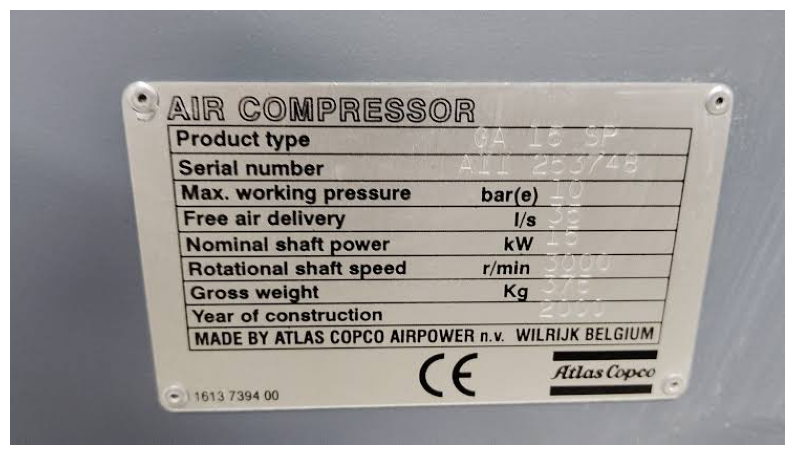

In [6]:
image_path = "test_images/nameplate_test.jpg"

img = cv2.imread(image_path)

if img is None:
    print("Image not found")
else:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10,6))
    plt.imshow(img_rgb)
    plt.axis("off")
    plt.show()

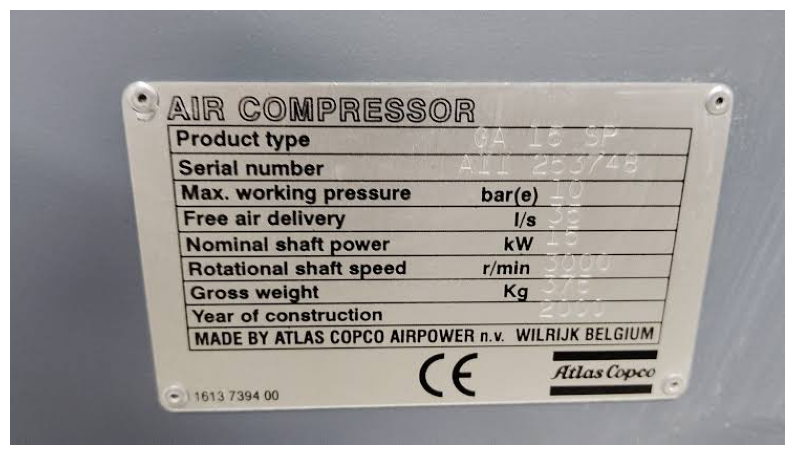

In [7]:
image_path = "test_images/nameplate_test.jpg"

img = cv2.imread(image_path)

if img is None:
    print("Image not found")
else:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10,6))
    plt.imshow(img_rgb)
    plt.axis("off")
    plt.show()

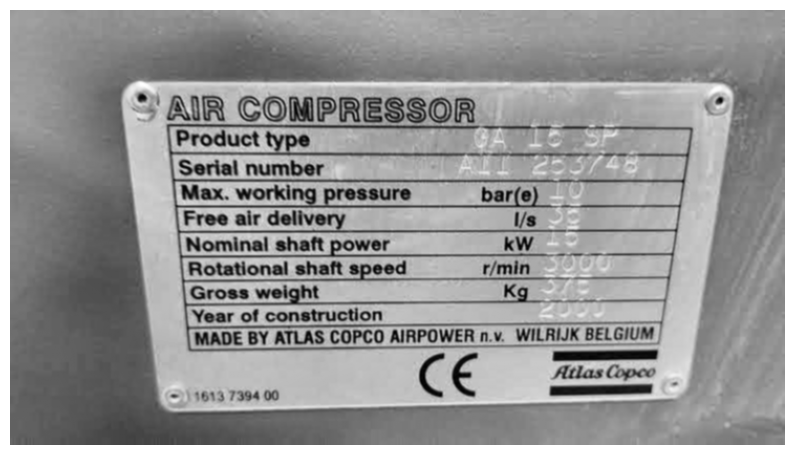

In [8]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Improve contrast
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8,8)
)

enhanced = clahe.apply(gray)

# Reduce noise
enhanced = cv2.GaussianBlur(
    enhanced,
    (3,3),
    0
)

plt.figure(figsize=(10,6))
plt.imshow(enhanced, cmap="gray")
plt.axis("off")
plt.show()

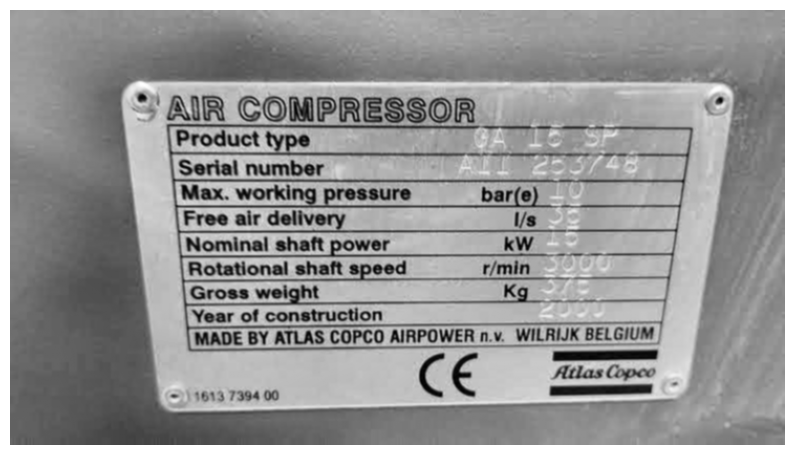

In [9]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Improve contrast
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8,8)
)

enhanced = clahe.apply(gray)

# Reduce noise
enhanced = cv2.GaussianBlur(
    enhanced,
    (3,3),
    0
)

plt.figure(figsize=(10,6))
plt.imshow(enhanced, cmap="gray")
plt.axis("off")
plt.show()

In [10]:
results = reader.readtext(enhanced)

for bbox, text, confidence in results:
    print(
        f"{text:30} | confidence = {confidence:.2f}"
    )

C:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


AiR COMPRESSOR                 | confidence = 0.59
Product type                   | confidence = 0.71
"                              | confidence = 0.03
13                             | confidence = 0.10
SF                             | confidence = 0.43
Seral number                   | confidence = 0.68
233786                         | confidence = 0.05
Max_working pressure _         | confidence = 0.41
bar(e                          | confidence = 0.66
3                              | confidence = 0.03
Free air delivery              | confidence = 0.29
Us                             | confidence = 0.17
Nominal shalt power            | confidence = 0.47
kW                             | confidence = 0.62
Retational shalt epeed         | confidence = 0.48
IImin                          | confidence = 0.26
3                              | confidence = 0.07
Gross welght                   | confidence = 0.70
Kg                             | confidence = 0.98
Year ol constructlon           

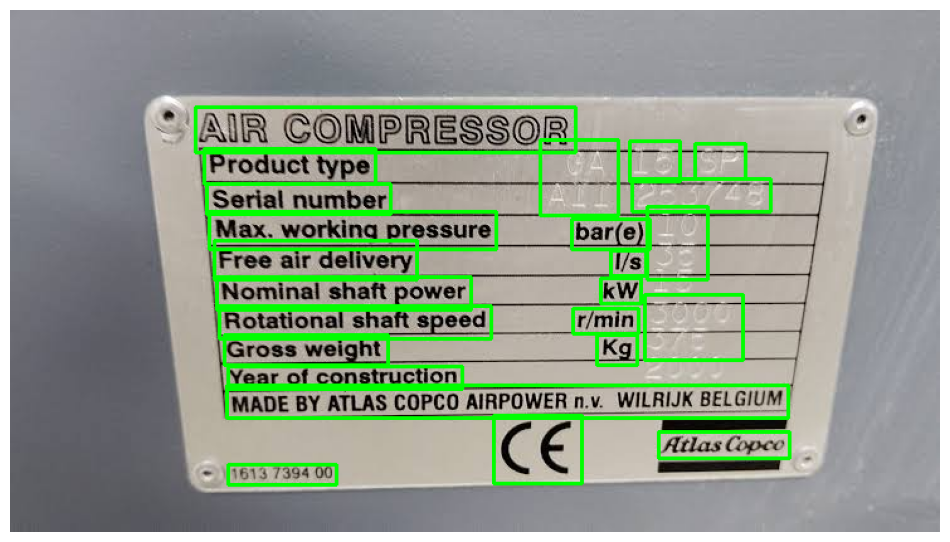

In [11]:
display_img = img_rgb.copy()

for bbox, text, confidence in results:

    points = np.array(
        bbox,
        dtype=np.int32
    )

    cv2.polylines(
        display_img,
        [points],
        True,
        (0,255,0),
        2
    )

plt.figure(figsize=(12,8))
plt.imshow(display_img)
plt.axis("off")
plt.show()

In [12]:
ocr_text = " ".join(
    [text for _, text, _ in results]
)

print(ocr_text)

AiR COMPRESSOR Product type " 13 SF Seral number 233786 Max_working pressure _ bar(e 3 Free air delivery Us Nominal shalt power kW Retational shalt epeed IImin 3 Gross welght Kg Year ol constructlon MADEBY AILAS COPCO NRPOWER nV_WILRIJK BEL GIUM (€ Atlas Copro 461y 7394 00


In [13]:
def extract_equipment_data(text):

    text_upper = text.upper()

    data = {
        "power_kw": None,
        "voltage_v": None,
        "speed_rpm": None,
        "frequency_hz": None,
        "current_a": None,
        "ip_rating": None
    }

    power = re.search(
        r"(\d+(?:\.\d+)?)\s*KW",
        text_upper
    )

    voltage = re.search(
        r"(\d+(?:\.\d+)?)\s*V\b",
        text_upper
    )

    rpm = re.search(
        r"(\d+(?:\.\d+)?)\s*RPM",
        text_upper
    )

    frequency = re.search(
        r"(\d+(?:\.\d+)?)\s*HZ",
        text_upper
    )

    current = re.search(
        r"(\d+(?:\.\d+)?)\s*A\b",
        text_upper
    )

    ip_rating = re.search(
        r"IP\s*(\d{2})",
        text_upper
    )

    if power:
        data["power_kw"] = float(power.group(1))

    if voltage:
        data["voltage_v"] = float(voltage.group(1))

    if rpm:
        data["speed_rpm"] = float(rpm.group(1))

    if frequency:
        data["frequency_hz"] = float(frequency.group(1))

    if current:
        data["current_a"] = float(current.group(1))

    if ip_rating:
        data["ip_rating"] = "IP" + ip_rating.group(1)

    return data

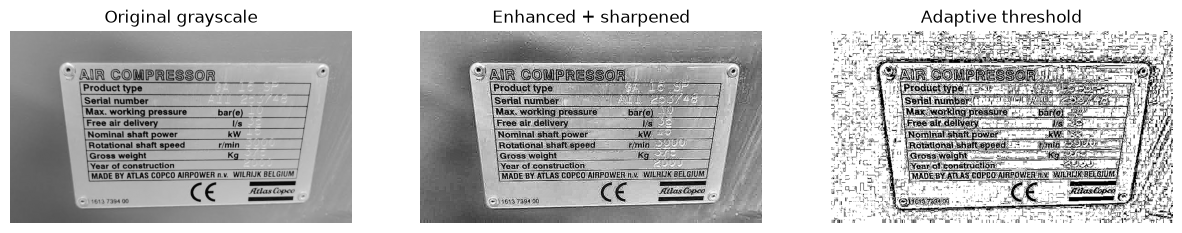

In [14]:
# Create multiple enhanced versions of the image
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Strong local contrast enhancement
clahe = cv2.createCLAHE(
    clipLimit=3.0,
    tileGridSize=(8, 8)
)

enhanced = clahe.apply(gray)

# Sharpen
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened = cv2.filter2D(
    enhanced,
    -1,
    kernel
)

# Adaptive threshold version
thresholded = cv2.adaptiveThreshold(
    sharpened,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    8
)

fig = plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sharpened, cmap="gray")
plt.title("Enhanced + sharpened")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(thresholded, cmap="gray")
plt.title("Adaptive threshold")
plt.axis("off")

plt.show()

In [15]:
ocr_versions = {
    "original": gray,
    "enhanced": sharpened,
    "thresholded": thresholded
}

all_results = {}

for name, image_version in ocr_versions.items():

    results_version = reader.readtext(
        image_version,
        detail=1
    )

    all_results[name] = results_version

    print("\n---", name.upper(), "---")

    for bbox, text, confidence in results_version:
        print(
            f"{text:35} | confidence={confidence:.2f}"
        )


--- ORIGINAL ---
AiR COMPRESSOR                      | confidence=0.71
Product type                        | confidence=0.78
Serial number                       | confidence=0.99
7774767                             | confidence=0.02
Max. working pressure               | confidence=0.58
bar(e)_                             | confidence=0.61
Free air delivery _                 | confidence=0.16
Ws                                  | confidence=0.37
Nominal shatt power                 | confidence=0.57
kw                                  | confidence=0.40
Rotational shalt speed              | confidence=0.74
Ilmin                               | confidence=0.31
Gross Weight                        | confidence=0.59
Kg_                                 | confidence=0.73
Year of construction                | confidence=0.95
MADE BY ATLAS COPCO AIRPOWER nV_WILRIJK BEL GIUM | confidence=0.69
(€                                  | confidence=0.93
Atlas Copco                         | confidence=0.

In [16]:
combined_text_parts = []

for version_name, version_results in all_results.items():

    for _, text, confidence in version_results:

        if confidence > 0.25:
            combined_text_parts.append(text)

combined_text = " ".join(combined_text_parts)

print(combined_text)

AiR COMPRESSOR Product type Serial number Max. working pressure bar(e)_ Ws Nominal shatt power kw Rotational shalt speed Ilmin Gross Weight Kg_ Year of construction MADE BY ATLAS COPCO AIRPOWER nV_WILRIJK BEL GIUM (€ Atlas Copco 1613 7394 00 AlR COMPRESSOR Preducitvpe Serial numba Max working pressure barfo Freeatrdelivery Nominal Shattpower KW 42 Imin Grossweight Kql Year Q conatruction C€ 23 @MPRESZ Gon


In [17]:
equipment_data = extract_equipment_data(
    combined_text
)

equipment_data

{'power_kw': None,
 'voltage_v': None,
 'speed_rpm': None,
 'frequency_hz': None,
 'current_a': None,
 'ip_rating': None}

In [18]:
def extract_nameplate_data(text):

    text_upper = text.upper()

    data = {
        "equipment_type": None,
        "manufacturer": None,
        "serial_number": None,
        "max_working_pressure_bar": None,
        "free_air_delivery_ls": None,
        "shaft_power_kw": None,
        "rotational_speed_rpm": None,
        "gross_weight_kg": None,
        "year_of_construction": None
    }

    # Equipment
    if "AIR COMPRESSOR" in text_upper:
        data["equipment_type"] = "Air Compressor"

    # Manufacturer
    if "ATLAS COPCO" in text_upper:
        data["manufacturer"] = "Atlas Copco"

    # Serial number - simple generic pattern
    serial_match = re.search(
        r"SERIAL\s*NUMBER\s*([A-Z0-9\-]+)",
        text_upper
    )

    if serial_match:
        data["serial_number"] = serial_match.group(1)

    # Pressure
    pressure_match = re.search(
        r"(\d+(?:\.\d+)?)\s*BAR",
        text_upper
    )

    if pressure_match:
        data["max_working_pressure_bar"] = float(
            pressure_match.group(1)
        )

    # Free air delivery
    air_match = re.search(
        r"(\d+(?:\.\d+)?)\s*L/S",
        text_upper
    )

    if air_match:
        data["free_air_delivery_ls"] = float(
            air_match.group(1)
        )

    # Power
    power_match = re.search(
        r"(\d+(?:\.\d+)?)\s*KW",
        text_upper
    )

    if power_match:
        data["shaft_power_kw"] = float(
            power_match.group(1)
        )

    # RPM / r/min
    rpm_match = re.search(
        r"(\d+(?:\.\d+)?)\s*(?:RPM|R/MIN)",
        text_upper
    )

    if rpm_match:
        data["rotational_speed_rpm"] = float(
            rpm_match.group(1)
        )

    # Weight
    weight_match = re.search(
        r"(\d+(?:\.\d+)?)\s*KG",
        text_upper
    )

    if weight_match:
        data["gross_weight_kg"] = float(
            weight_match.group(1)
        )

    # Year
    year_match = re.search(
        r"\b(19\d{2}|20\d{2})\b",
        text_upper
    )

    if year_match:
        data["year_of_construction"] = int(
            year_match.group(1)
        )

    return data

In [19]:
nameplate_data = extract_nameplate_data(
    combined_text
)

nameplate_data

{'equipment_type': 'Air Compressor',
 'manufacturer': 'Atlas Copco',
 'serial_number': 'MAX',
 'max_working_pressure_bar': None,
 'free_air_delivery_ls': None,
 'shaft_power_kw': None,
 'rotational_speed_rpm': None,
 'gross_weight_kg': None,
 'year_of_construction': None}

In [20]:
{
    "equipment_type": "Air Compressor",
    "manufacturer": "Atlas Copco",
    "serial_number": "...",
    "max_working_pressure_bar": ...,
    "free_air_delivery_ls": ...,
    "shaft_power_kw": ...,
    "rotational_speed_rpm": ...,
    "gross_weight_kg": ...,
    "year_of_construction": ...
}

{'equipment_type': 'Air Compressor',
 'manufacturer': 'Atlas Copco',
 'serial_number': '...',
 'max_working_pressure_bar': Ellipsis,
 'free_air_delivery_ls': Ellipsis,
 'shaft_power_kw': Ellipsis,
 'rotational_speed_rpm': Ellipsis,
 'gross_weight_kg': Ellipsis,
 'year_of_construction': Ellipsis}

In [21]:
nameplate_data

{'equipment_type': 'Air Compressor',
 'manufacturer': 'Atlas Copco',
 'serial_number': 'MAX',
 'max_working_pressure_bar': None,
 'free_air_delivery_ls': None,
 'shaft_power_kw': None,
 'rotational_speed_rpm': None,
 'gross_weight_kg': None,
 'year_of_construction': None}

In [22]:
import cv2
import numpy as np
import easyocr

reader = easyocr.Reader(['en'], gpu=False)

# Original OCR results from the full image
full_results = reader.readtext(img)

LABELS = {
    "Product type": "product_type",
    "Serial number": "serial_number",
    "Max. working pressure": "max_working_pressure",
    "Free air delivery": "free_air_delivery",
    "Nominal shaft power": "shaft_power",
    "Rotational shaft speed": "rotational_speed",
    "Gross weight": "gross_weight",
    "Year of construction": "year"
}

def center_y(box):
    return sum(p[1] for p in box) / 4

def right_x(box):
    return max(p[0] for p in box)

def read_value_to_right(img, box):
    h, w = img.shape[:2]

    y_values = [p[1] for p in box]

    y1 = max(0, int(min(y_values) - 8))
    y2 = min(h, int(max(y_values) + 8))

    x1 = int(right_x(box) + 10)
    x2 = min(w, x1 + 350)

    crop = img[y1:y2, x1:x2]

    if crop.size == 0:
        return None

    # Upscale
    crop = cv2.resize(
        crop,
        None,
        fx=4,
        fy=4,
        interpolation=cv2.INTER_CUBIC
    )

    gray_crop = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2GRAY
    )

    # Improve faint engraving
    clahe = cv2.createCLAHE(
        clipLimit=4.0,
        tileGridSize=(8,8)
    )

    enhanced = clahe.apply(gray_crop)

    result = reader.readtext(
        enhanced,
        detail=0,
        paragraph=False
    )

    if result:
        return " ".join(result)

    return None


extracted = {}

for bbox, text, confidence in full_results:

    text_clean = text.strip().lower()

    for label, key in LABELS.items():

        if label.lower() in text_clean:

            value = read_value_to_right(
                img,
                bbox
            )

            extracted[key] = value

extracted

Using CPU. Note: This module is much faster with a GPU.


{'product_type': '',
 'serial_number': None,
 'max_working_pressure': 'barfe',
 'free_air_delivery': 'nn Lcae Vs',
 'gross_weight': ' Kq',
 'year': None}